In [1]:
# ============================================================
# CELL 1: IMPORT LIBRARIES
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import SGD, RMSprop, Adam
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler

print("TensorFlow version:", tf.__version__)

# Check GPU
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: []


In [2]:
# ============================================================
# CELL 2: RANDOM SEED
# ============================================================

SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

print("Random seed set to", SEED)

Random seed set to 42


In [3]:
# ============================================================
# CELL 3: LOAD FASHION-MNIST
# ============================================================

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


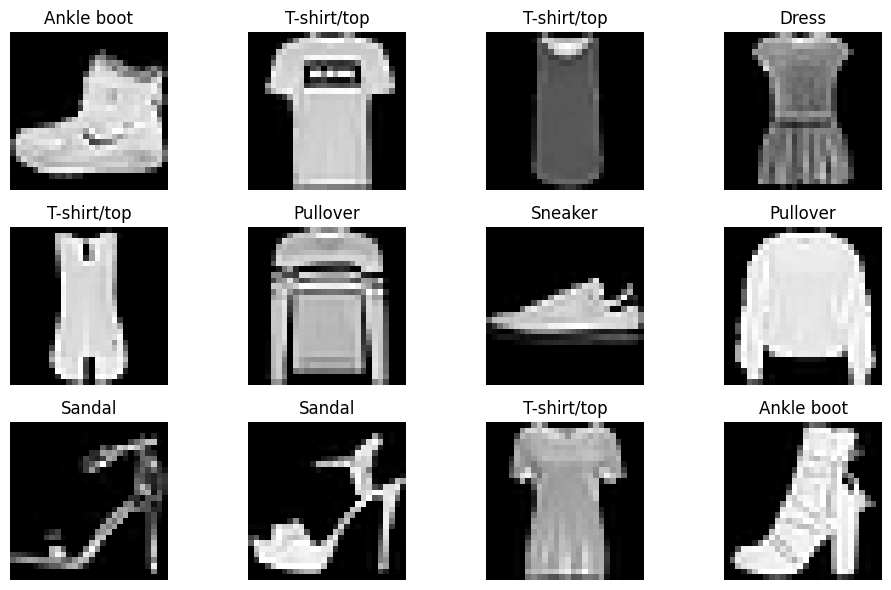

In [4]:
# ============================================================
# CELL 4: DISPLAY SAMPLE IMAGES
# ============================================================

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_train[i], cmap="gray")

    plt.title(class_names[y_train[i]])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# CELL 5: PREPROCESS DATA
# ============================================================

# Convert pixel values to float
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
# From (60000, 28, 28)
# To   (60000, 28, 28, 1)

x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Test shape: (10000, 28, 28, 1)


In [6]:
# ============================================================
# CELL 6: TRAIN / VALIDATION SPLIT
# ============================================================

x_train_final = x_train[:48000]
y_train_final = y_train[:48000]

x_val = x_train[48000:]
y_val = y_train[48000:]

print("Training set:", x_train_final.shape)
print("Validation set:", x_val.shape)
print("Test set:", x_test.shape)

Training set: (48000, 28, 28, 1)
Validation set: (12000, 28, 28, 1)
Test set: (10000, 28, 28, 1)


In [8]:
# ============================================================
# CELL 7: FIXED CNN ARCHITECTURE
# ============================================================

def create_model(
    l2_strength=0.0,
    dropout_rate=0.0,
    use_batch_norm=False
):

    model = models.Sequential()

    # --------------------------------------------------------
    # CONVOLUTIONAL BLOCK 1
    # --------------------------------------------------------

    model.add(
        layers.Conv2D(
            32,
            (3, 3),
            padding="same",
            activation="relu",
            kernel_regularizer=(
                regularizers.l2(l2_strength)
                if l2_strength > 0
                else None
            ),
            input_shape=(28, 28, 1)
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(
        layers.MaxPooling2D((2, 2))
    )


    # --------------------------------------------------------
    # CONVOLUTIONAL BLOCK 2
    # --------------------------------------------------------

    model.add(
        layers.Conv2D(
            64,
            (3, 3),
            padding="same",
            activation="relu",
            kernel_regularizer=(
                regularizers.l2(l2_strength)
                if l2_strength > 0
                else None
            )
        )
    )

    if use_batch_norm:
        model.add(layers.BatchNormalization())

    model.add(
        layers.MaxPooling2D((2, 2))
    )


    # --------------------------------------------------------
    # FULLY CONNECTED LAYER
    # --------------------------------------------------------

    model.add(layers.Flatten())

    model.add(
        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=(
                regularizers.l2(l2_strength)
                if l2_strength > 0
                else None
            )
        )
    )


    # --------------------------------------------------------
    # DROPOUT
    # --------------------------------------------------------

    if dropout_rate > 0:

        model.add(
            layers.Dropout(dropout_rate)
        )


    # --------------------------------------------------------
    # OUTPUT
    # --------------------------------------------------------

    model.add(
        layers.Dense(
            10,
            activation="softmax"
        )
    )

    return model

In [9]:
# ============================================================
# CELL 8: CHECK MODEL
# ============================================================

model = create_model()

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# ============================================================
# CELL 9: OPTIMIZERS
# ============================================================

def get_optimizer(name, learning_rate):

    if name == "SGD":

        return SGD(
            learning_rate=learning_rate
        )

    elif name == "Momentum":

        return SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    elif name == "RMSprop":

        return RMSprop(
            learning_rate=learning_rate
        )

    elif name == "Adam":

        return Adam(
            learning_rate=learning_rate
        )

    else:

        raise ValueError(
            "Unknown optimizer: " + name
        )

In [11]:
# ============================================================
# CELL 10: LEARNING RATE SCHEDULES
# ============================================================

INITIAL_LR = 0.001
TOTAL_EPOCHS = 20


# ------------------------------------------------------------
# STEP DECAY
# ------------------------------------------------------------

def step_decay(epoch, lr):

    if epoch < 7:
        return INITIAL_LR

    elif epoch < 14:
        return INITIAL_LR * 0.5

    else:
        return INITIAL_LR * 0.25


# ------------------------------------------------------------
# COSINE ANNEALING
# ------------------------------------------------------------

def cosine_annealing(epoch, lr):

    return (
        INITIAL_LR
        * 0.5
        * (
            1
            + np.cos(
                np.pi * epoch / TOTAL_EPOCHS
            )
        )
    )

In [12]:
# ============================================================
# CELL 11: TRAINING FUNCTION
# ============================================================

def train_experiment(
    experiment_name,
    optimizer_name="Adam",
    learning_rate=0.001,
    schedule=None,
    l2_strength=0.0,
    dropout_rate=0.0,
    use_batch_norm=False,
    use_early_stopping=False,
    epochs=TOTAL_EPOCHS
):

    print("\n")
    print("=" * 70)
    print("EXPERIMENT:", experiment_name)
    print("=" * 70)

    # --------------------------------------------------------
    # Create fixed CNN
    # --------------------------------------------------------

    model = create_model(
        l2_strength=l2_strength,
        dropout_rate=dropout_rate,
        use_batch_norm=use_batch_norm
    )


    # --------------------------------------------------------
    # Create optimizer
    # --------------------------------------------------------

    optimizer = get_optimizer(
        optimizer_name,
        learning_rate
    )


    # --------------------------------------------------------
    # Compile
    # --------------------------------------------------------

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )


    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    callbacks = []


    # Learning-rate schedule
    if schedule == "step":

        callbacks.append(
            LearningRateScheduler(
                step_decay,
                verbose=0
            )
        )

    elif schedule == "cosine":

        callbacks.append(
            LearningRateScheduler(
                cosine_annealing,
                verbose=0
            )
        )


    # Early stopping
    if use_early_stopping:

        callbacks.append(
            EarlyStopping(
                monitor="val_loss",
                patience=4,
                restore_best_weights=True,
                verbose=1
            )
        )


    # --------------------------------------------------------
    # Start timer
    # --------------------------------------------------------

    start_time = time.time()


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    history = model.fit(
        x_train_final,
        y_train_final,

        validation_data=(
            x_val,
            y_val
        ),

        epochs=epochs,

        batch_size=64,

        callbacks=callbacks,

        verbose=1
    )


    # --------------------------------------------------------
    # Training time
    # --------------------------------------------------------

    training_time = time.time() - start_time


    # --------------------------------------------------------
    # Get best validation results
    # --------------------------------------------------------

    best_val_accuracy = max(
        history.history["val_accuracy"]
    )

    best_val_loss = min(
        history.history["val_loss"]
    )


    final_train_accuracy = (
        history.history["accuracy"][-1]
    )

    final_val_accuracy = (
        history.history["val_accuracy"][-1]
    )


    print("\nTraining completed.")

    print(
        "Best validation accuracy:",
        round(best_val_accuracy * 100, 2),
        "%"
    )

    print(
        "Training time:",
        round(training_time, 2),
        "seconds"
    )


    return {

        "name": experiment_name,

        "model": model,

        "history": history,

        "training_time": training_time,

        "best_val_accuracy":
            best_val_accuracy,

        "best_val_loss":
            best_val_loss,

        "final_train_accuracy":
            final_train_accuracy,

        "final_val_accuracy":
            final_val_accuracy
    }

In [13]:
# ============================================================
# CELL 12: PLOT TRAINING / VALIDATION CURVES
# ============================================================

def plot_history(result):

    history = result["history"].history

    epochs = range(
        1,
        len(history["accuracy"]) + 1
    )


    # ========================================================
    # ACCURACY
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(
        result["name"] +
        " - Training vs Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()

    plt.grid(True)

    plt.show()


    # ========================================================
    # LOSS
    # ========================================================

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        result["name"] +
        " - Training vs Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()

    plt.grid(True)

    plt.show()



EXPERIMENT: Baseline - SGD
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - accuracy: 0.6453 - loss: 1.0253 - val_accuracy: 0.7840 - val_loss: 0.6294
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 68ms/step - accuracy: 0.7788 - loss: 0.6105 - val_accuracy: 0.8068 - val_loss: 0.5417
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.8056 - loss: 0.5331 - val_accuracy: 0.8263 - val_loss: 0.4931
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.8250 - loss: 0.4846 - val_accuracy: 0.8372 - val_loss: 0.4608
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 66ms/step - accuracy: 0.8379 - loss: 0.4498 - val_accuracy: 0.8468 - val_loss: 0.4371
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - accuracy: 0.8480 - loss: 0.4230 - val_accuracy: 0.8537 - val_loss: 0.4175
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 70ms/step - accuracy: 0.8561 - loss: 0.4022 - val_accuracy: 0.8609 - val_loss: 0.4013
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 79s 66ms/step - accur

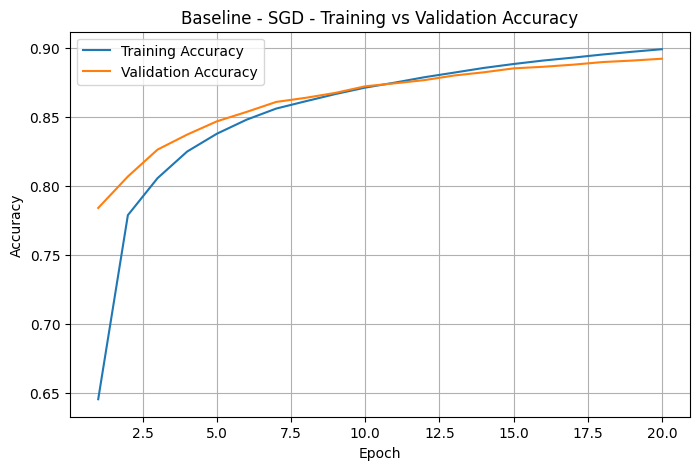

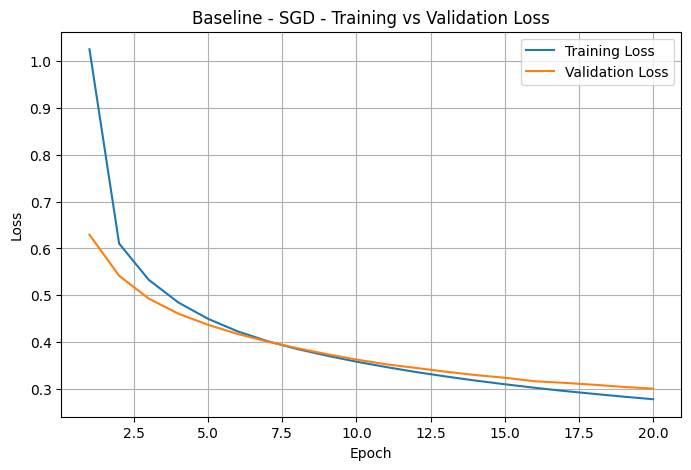

In [14]:
# ============================================================
# CELL 13: BASELINE
# ============================================================

baseline = train_experiment(
    experiment_name="Baseline - SGD",

    optimizer_name="SGD",

    learning_rate=0.01,

    epochs=TOTAL_EPOCHS
)

plot_history(baseline)



EXPERIMENT: SGD + Momentum
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 51s 68ms/step - accuracy: 0.7757 - loss: 0.6168 - val_accuracy: 0.8554 - val_loss: 0.4060
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 51s 67ms/step - accuracy: 0.8664 - loss: 0.3692 - val_accuracy: 0.8783 - val_loss: 0.3398
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 66ms/step - accuracy: 0.8863 - loss: 0.3159 - val_accuracy: 0.8867 - val_loss: 0.3164
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 68ms/step - accuracy: 0.8978 - loss: 0.2836 - val_accuracy: 0.8941 - val_loss: 0.2960
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 67ms/step - accuracy: 0.9054 - loss: 0.2591 - val_accuracy: 0.8989 - val_loss: 0.2789
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 51s 68ms/step - accuracy: 0.9126 - loss: 0.2381 - val_accuracy: 0.9021 - val_loss: 0.2704
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 51s 68ms/step - accuracy: 0.9195 - loss: 0.2207 - val_accuracy: 0.9063 - val_loss: 0.2612
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 68ms/step - accur

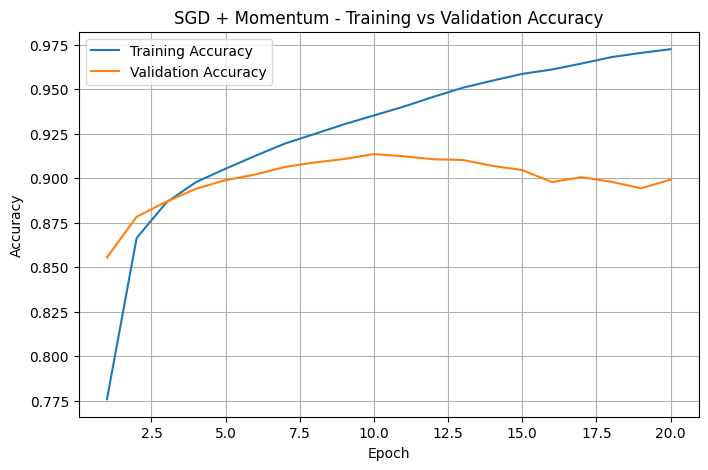

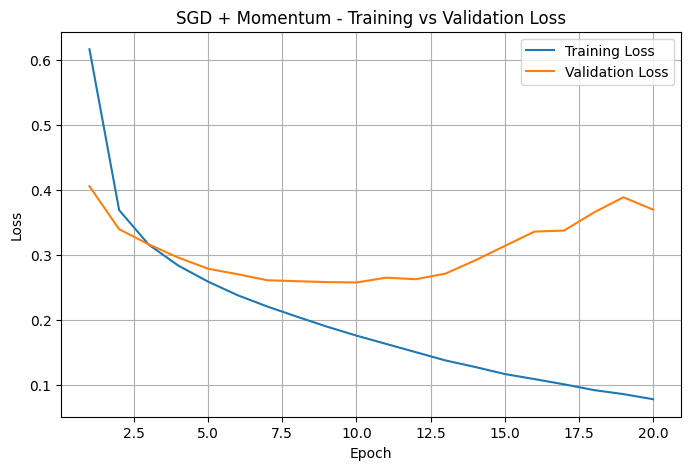

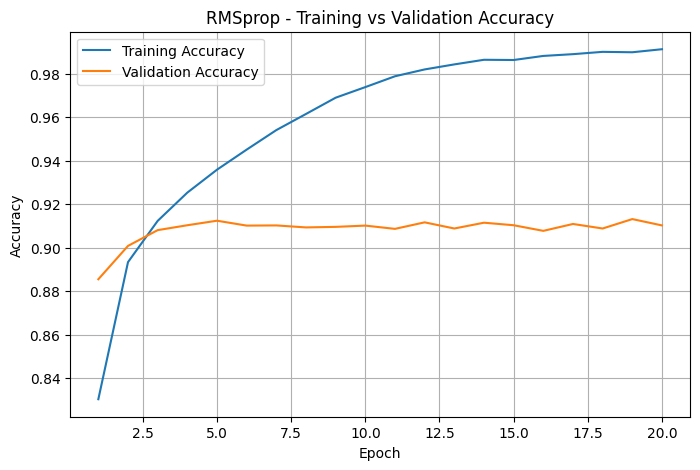

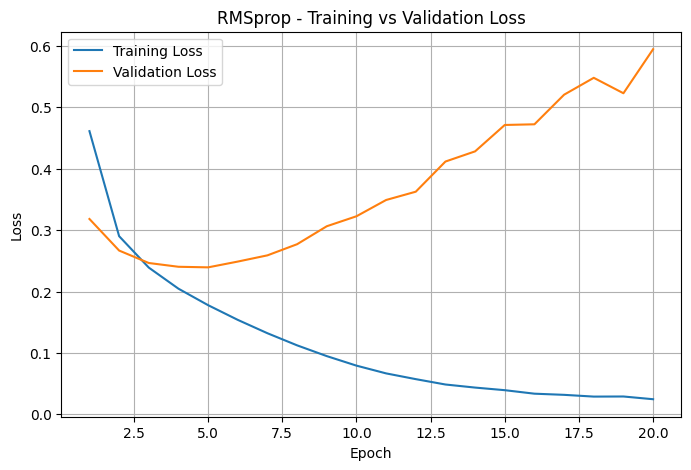

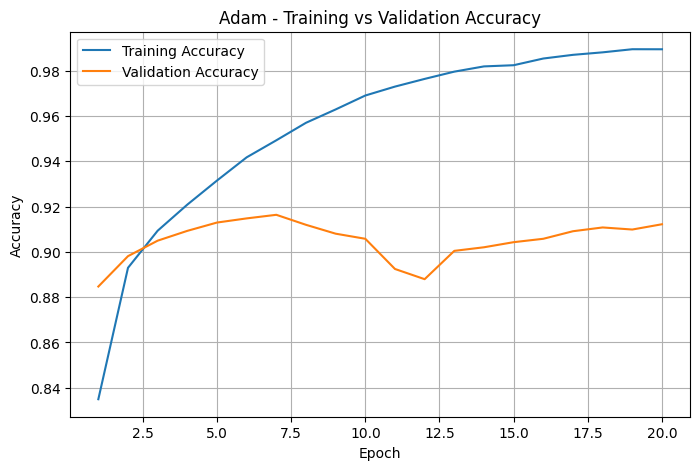

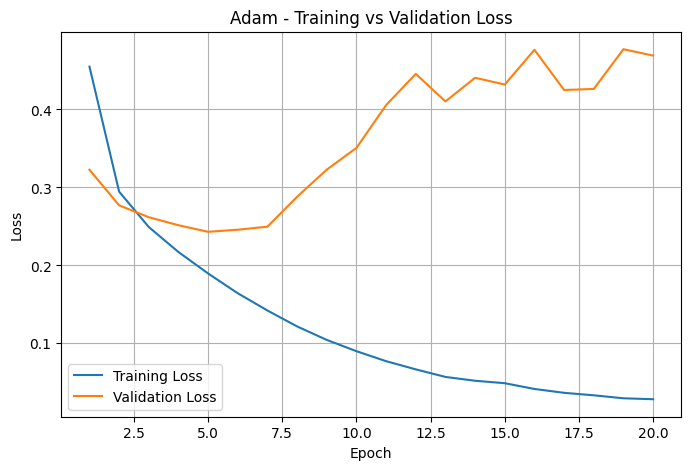

In [15]:
# ============================================================
# CELL 14: OPTIMIZER COMPARISON
# ============================================================

momentum = train_experiment(
    experiment_name="SGD + Momentum",

    optimizer_name="Momentum",

    learning_rate=0.01,

    epochs=TOTAL_EPOCHS
)


rmsprop = train_experiment(
    experiment_name="RMSprop",

    optimizer_name="RMSprop",

    learning_rate=0.001,

    epochs=TOTAL_EPOCHS
)


adam = train_experiment(
    experiment_name="Adam",

    optimizer_name="Adam",

    learning_rate=0.001,

    epochs=TOTAL_EPOCHS
)


plot_history(momentum)
plot_history(rmsprop)
plot_history(adam)



EXPERIMENT: Adam + Step Decay
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 58s 76ms/step - accuracy: 0.8389 - loss: 0.4476 - val_accuracy: 0.8864 - val_loss: 0.3153 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 72ms/step - accuracy: 0.8942 - loss: 0.2933 - val_accuracy: 0.8986 - val_loss: 0.2768 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 70ms/step - accuracy: 0.9101 - loss: 0.2464 - val_accuracy: 0.9073 - val_loss: 0.2568 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 69ms/step - accuracy: 0.9221 - loss: 0.2130 - val_accuracy: 0.9105 - val_loss: 0.2476 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 72ms/step - accuracy: 0.9323 - loss: 0.1840 - val_accuracy: 0.9137 - val_loss: 0.2430 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 70ms/step - accuracy: 0.9431 - loss: 0.1583 - val_accuracy: 0.9143 - val_loss: 0.2513 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 

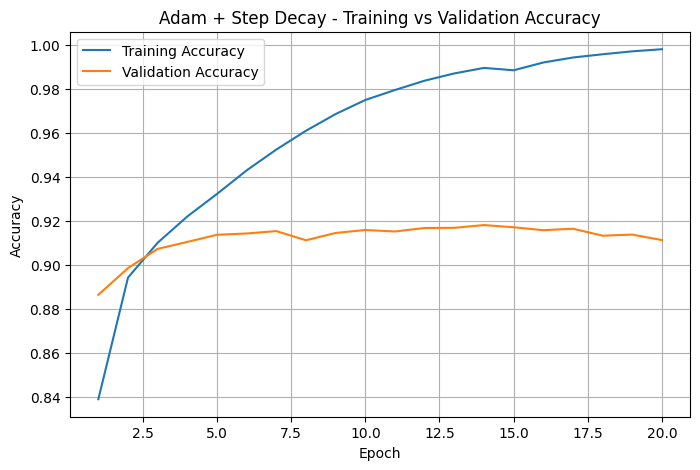

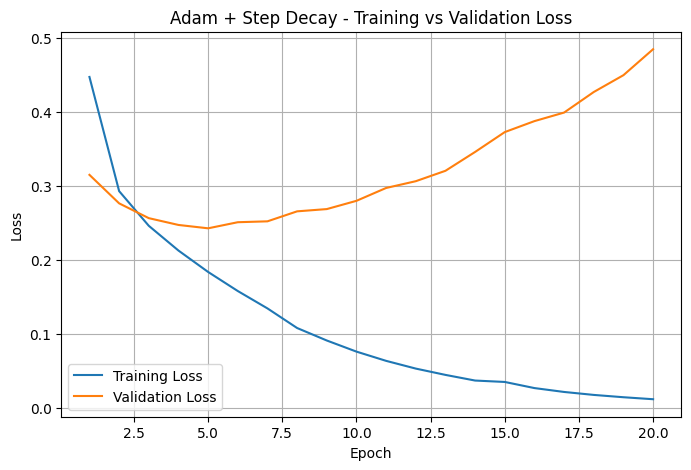

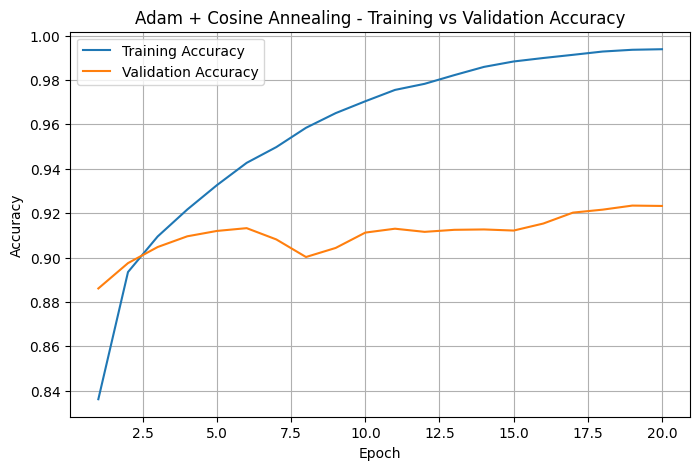

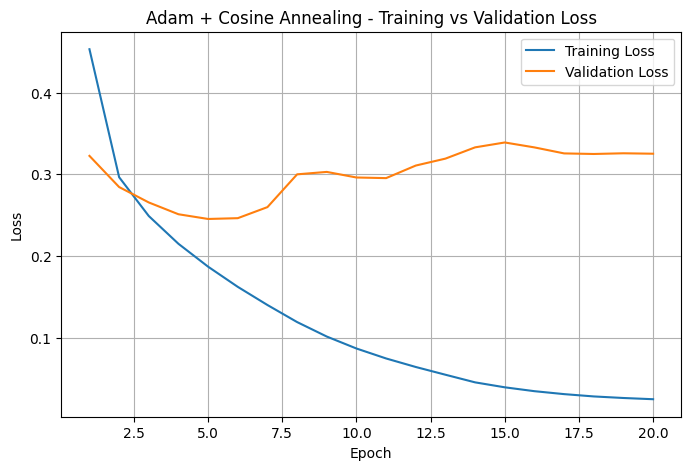

In [16]:
# ============================================================
# CELL 15: LEARNING RATE SCHEDULES
# ============================================================

adam_step = train_experiment(
    experiment_name="Adam + Step Decay",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="step",

    epochs=TOTAL_EPOCHS
)


adam_cosine = train_experiment(
    experiment_name="Adam + Cosine Annealing",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    epochs=TOTAL_EPOCHS
)


plot_history(adam_step)
plot_history(adam_cosine)



EXPERIMENT: No Regularization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 70ms/step - accuracy: 0.8342 - loss: 0.4641 - val_accuracy: 0.8824 - val_loss: 0.3338 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 70ms/step - accuracy: 0.8907 - loss: 0.3045 - val_accuracy: 0.8942 - val_loss: 0.2866 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 52s 70ms/step - accuracy: 0.9079 - loss: 0.2533 - val_accuracy: 0.9038 - val_loss: 0.2649 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 69ms/step - accuracy: 0.9199 - loss: 0.2180 - val_accuracy: 0.9082 - val_loss: 0.2513 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 69ms/step - accuracy: 0.9305 - loss: 0.1896 - val_accuracy: 0.9098 - val_loss: 0.2471 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 72ms/step - accuracy: 0.9407 - loss: 0.1644 - val_accuracy: 0.9136 - val_loss: 0.2461 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━━━

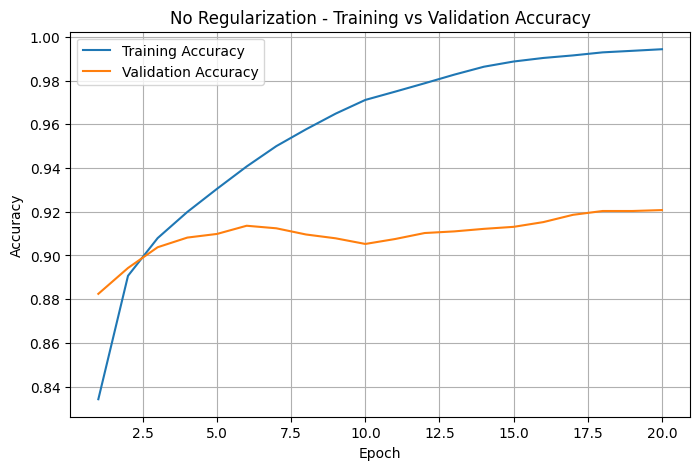

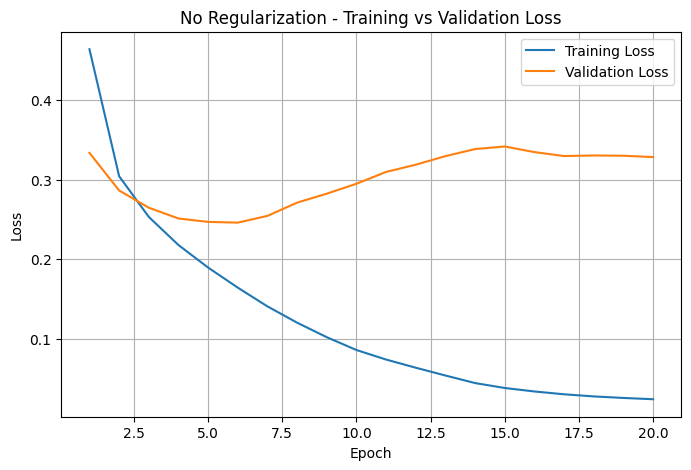

In [17]:
# ============================================================
# CELL 16: NO REGULARIZATION
# ============================================================

no_regularization = train_experiment(

    experiment_name="No Regularization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    epochs=TOTAL_EPOCHS
)

plot_history(no_regularization)



EXPERIMENT: L2 Regularization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 71ms/step - accuracy: 0.8325 - loss: 0.4922 - val_accuracy: 0.8808 - val_loss: 0.3704 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8899 - loss: 0.3446 - val_accuracy: 0.8957 - val_loss: 0.3308 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.9052 - loss: 0.3030 - val_accuracy: 0.9013 - val_loss: 0.3157 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 71ms/step - accuracy: 0.9151 - loss: 0.2768 - val_accuracy: 0.9072 - val_loss: 0.3039 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 73ms/step - accuracy: 0.9239 - loss: 0.2576 - val_accuracy: 0.9091 - val_loss: 0.3005 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.9320 - loss: 0.2408 - val_accuracy: 0.9103 - val_loss: 0.3029 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━━━

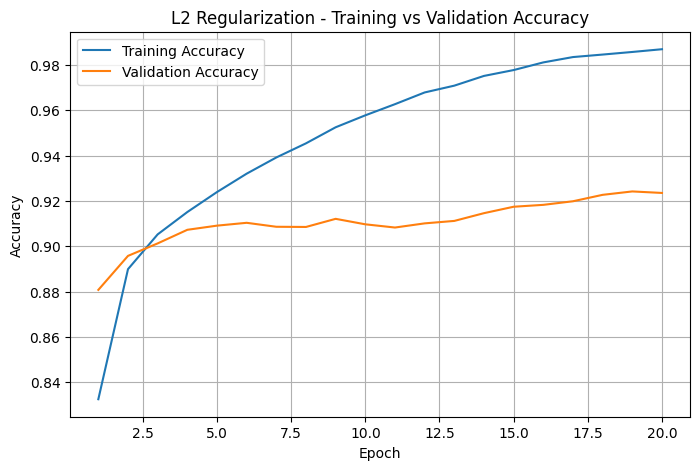

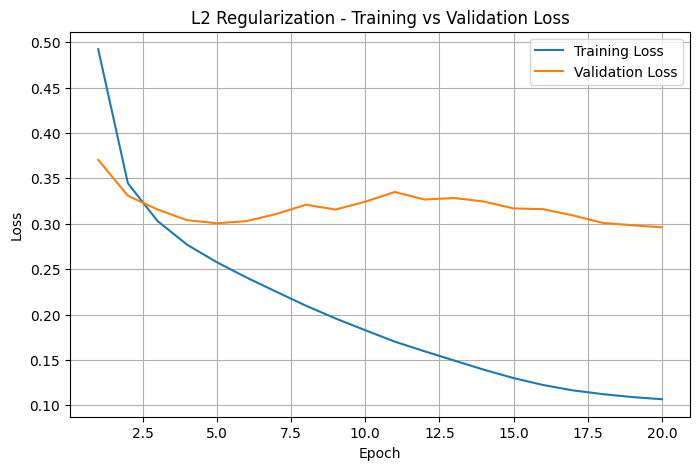

In [18]:
# ============================================================
# CELL 17: L2 REGULARIZATION
# ============================================================

l2_model = train_experiment(

    experiment_name="L2 Regularization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    l2_strength=0.0001,

    epochs=TOTAL_EPOCHS
)

plot_history(l2_model)



EXPERIMENT: Dropout
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 71ms/step - accuracy: 0.7875 - loss: 0.5880 - val_accuracy: 0.8681 - val_loss: 0.3689 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.8613 - loss: 0.3888 - val_accuracy: 0.8895 - val_loss: 0.3015 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 70ms/step - accuracy: 0.8811 - loss: 0.3341 - val_accuracy: 0.8948 - val_loss: 0.2798 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 52s 70ms/step - accuracy: 0.8925 - loss: 0.2980 - val_accuracy: 0.8957 - val_loss: 0.2790 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 85s 73ms/step - accuracy: 0.9006 - loss: 0.2741 - val_accuracy: 0.9085 - val_loss: 0.2537 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 72ms/step - accuracy: 0.9078 - loss: 0.2508 - val_accuracy: 0.9098 - val_loss: 0.2446 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━

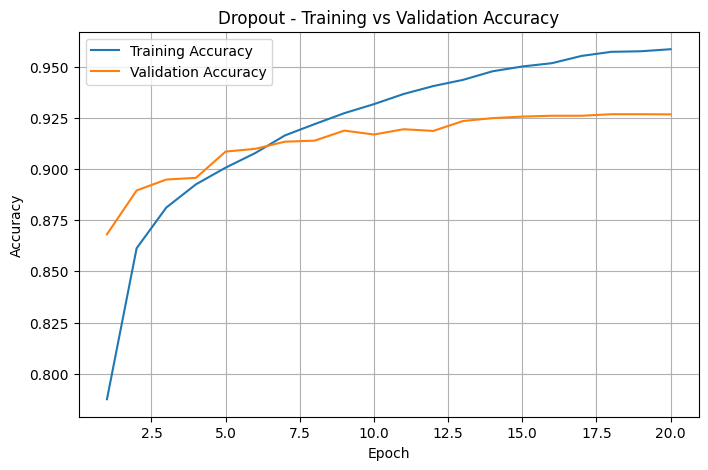

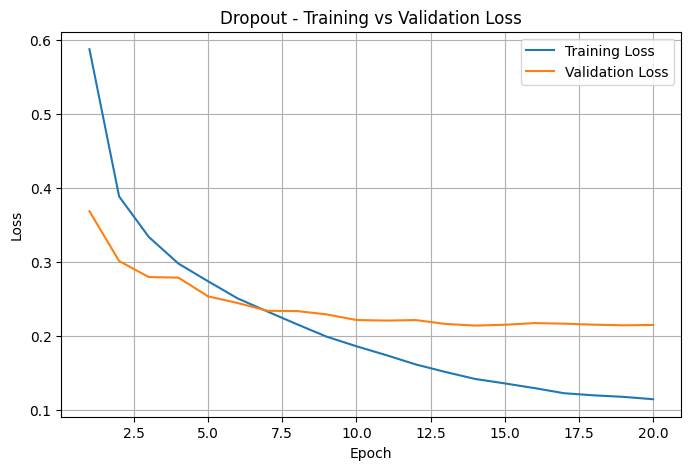

In [19]:
# ============================================================
# CELL 18: DROPOUT
# ============================================================

dropout_model = train_experiment(

    experiment_name="Dropout",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    dropout_rate=0.5,

    epochs=TOTAL_EPOCHS
)

plot_history(dropout_model)



EXPERIMENT: Early Stopping
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 70ms/step - accuracy: 0.8359 - loss: 0.4503 - val_accuracy: 0.8839 - val_loss: 0.3235 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.8955 - loss: 0.2925 - val_accuracy: 0.8984 - val_loss: 0.2780 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 70ms/step - accuracy: 0.9119 - loss: 0.2434 - val_accuracy: 0.9090 - val_loss: 0.2535 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 73ms/step - accuracy: 0.9243 - loss: 0.2095 - val_accuracy: 0.9122 - val_loss: 0.2418 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 71ms/step - accuracy: 0.9347 - loss: 0.1819 - val_accuracy: 0.9147 - val_loss: 0.2413 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 70ms/step - accuracy: 0.9431 - loss: 0.1579 - val_accuracy: 0.9124 - val_loss: 0.2482 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━━━━━━

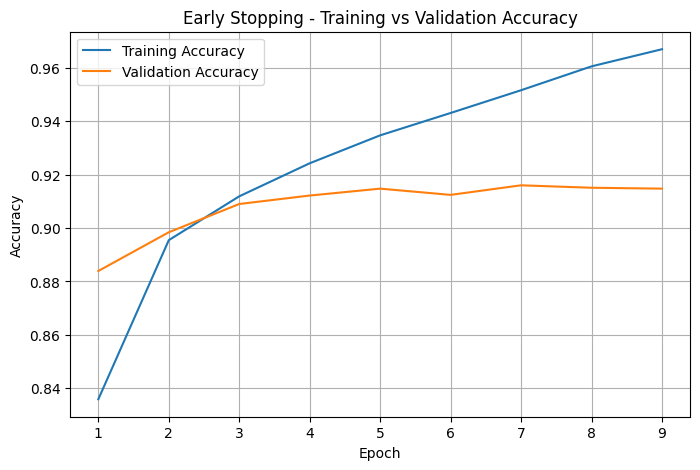

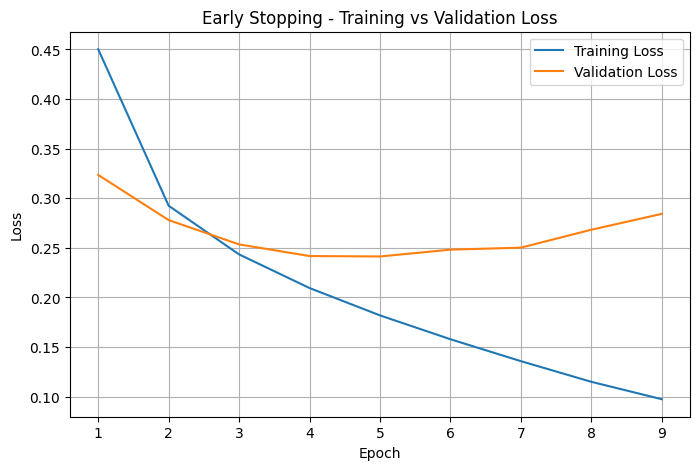

In [20]:
# ============================================================
# CELL 19: EARLY STOPPING
# ============================================================

early_stop_model = train_experiment(

    experiment_name="Early Stopping",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    use_early_stopping=True,

    epochs=TOTAL_EPOCHS
)

plot_history(early_stop_model)



EXPERIMENT: Batch Normalization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 73s 95ms/step - accuracy: 0.8653 - loss: 0.3763 - val_accuracy: 0.8826 - val_loss: 0.3219 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 96ms/step - accuracy: 0.9080 - loss: 0.2497 - val_accuracy: 0.9051 - val_loss: 0.2594 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 95ms/step - accuracy: 0.9258 - loss: 0.1993 - val_accuracy: 0.9114 - val_loss: 0.2404 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 72s 97ms/step - accuracy: 0.9389 - loss: 0.1642 - val_accuracy: 0.9043 - val_loss: 0.2925 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 72s 96ms/step - accuracy: 0.9485 - loss: 0.1372 - val_accuracy: 0.9052 - val_loss: 0.2850 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 73s 97ms/step - accuracy: 0.9574 - loss: 0.1149 - val_accuracy: 0.9161 - val_loss: 0.2630 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━

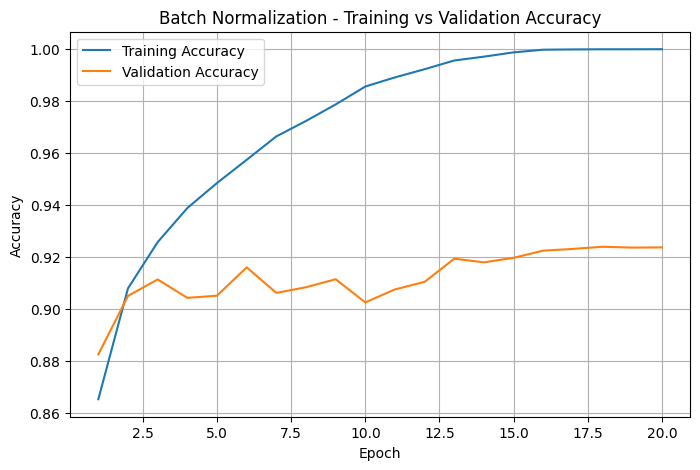

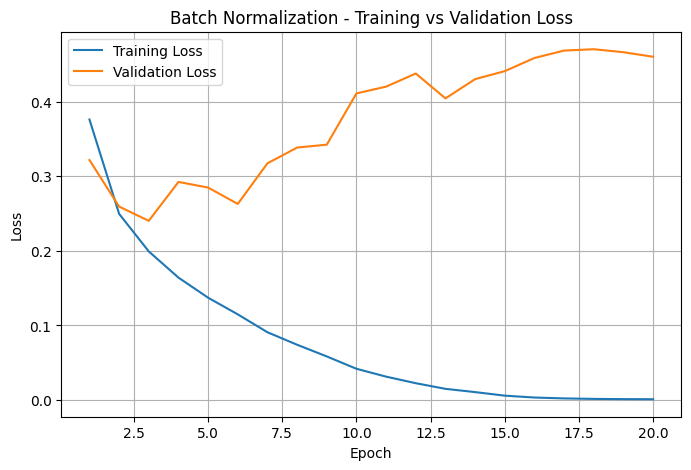

In [21]:
# ============================================================
# CELL 20: BATCH NORMALIZATION
# ============================================================

batch_norm_model = train_experiment(

    experiment_name="Batch Normalization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    use_batch_norm=True,

    epochs=TOTAL_EPOCHS
)

plot_history(batch_norm_model)



EXPERIMENT: L2 + Dropout
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 55s 72ms/step - accuracy: 0.7975 - loss: 0.6025 - val_accuracy: 0.8690 - val_loss: 0.3921 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 56s 74ms/step - accuracy: 0.8660 - loss: 0.4204 - val_accuracy: 0.8844 - val_loss: 0.3614 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 54s 72ms/step - accuracy: 0.8822 - loss: 0.3790 - val_accuracy: 0.8945 - val_loss: 0.3349 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 71ms/step - accuracy: 0.8923 - loss: 0.3535 - val_accuracy: 0.8983 - val_loss: 0.3287 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 74ms/step - accuracy: 0.9003 - loss: 0.3321 - val_accuracy: 0.9051 - val_loss: 0.3116 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 72ms/step - accuracy: 0.9075 - loss: 0.3152 - val_accuracy: 0.9047 - val_loss: 0.3136 - learning_rate: 8.5355e-04
Epoch 7/20
750/750 ━━━━━━━━━━

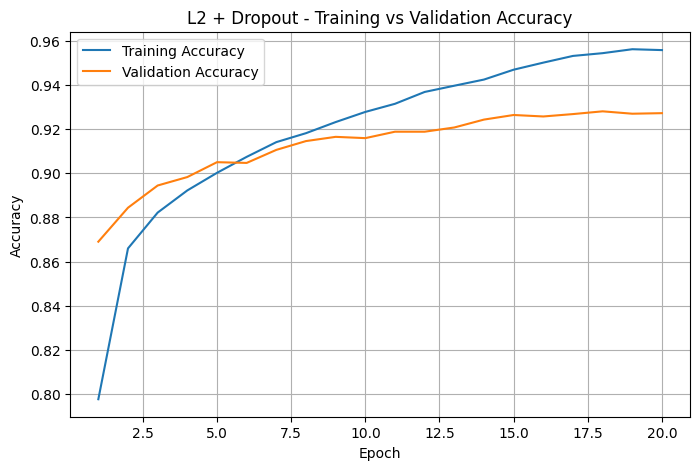

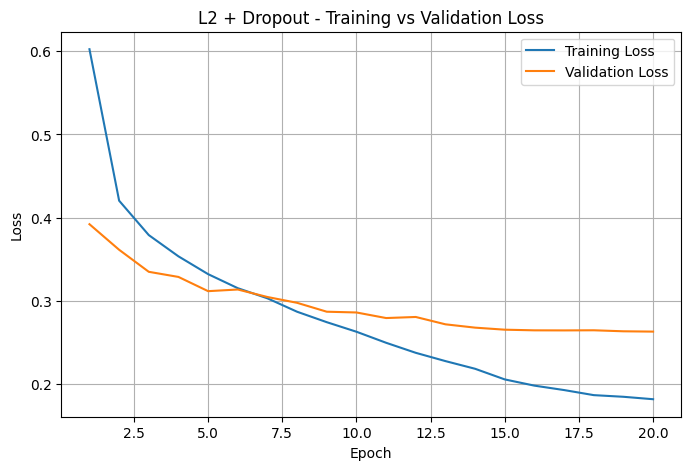

In [22]:
# ============================================================
# CELL 21: L2 + DROPOUT
# ============================================================

l2_dropout = train_experiment(

    experiment_name="L2 + Dropout",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    l2_strength=0.0001,

    dropout_rate=0.5,

    epochs=TOTAL_EPOCHS
)

plot_history(l2_dropout)



EXPERIMENT: L2 + Batch Normalization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 76s 99ms/step - accuracy: 0.8670 - loss: 0.4078 - val_accuracy: 0.8834 - val_loss: 0.3479 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 99ms/step - accuracy: 0.9089 - loss: 0.2795 - val_accuracy: 0.9021 - val_loss: 0.3100 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 96ms/step - accuracy: 0.9261 - loss: 0.2354 - val_accuracy: 0.8984 - val_loss: 0.3206 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - accuracy: 0.9377 - loss: 0.2093 - val_accuracy: 0.9104 - val_loss: 0.3088 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 84s 99ms/step - accuracy: 0.9452 - loss: 0.1918 - val_accuracy: 0.9082 - val_loss: 0.3301 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 98ms/step - accuracy: 0.9545 - loss: 0.1723 - val_accuracy: 0.8992 - val_loss: 0.3766 - learning_rate: 8.5355e-04
Epoch 7/20
750/75

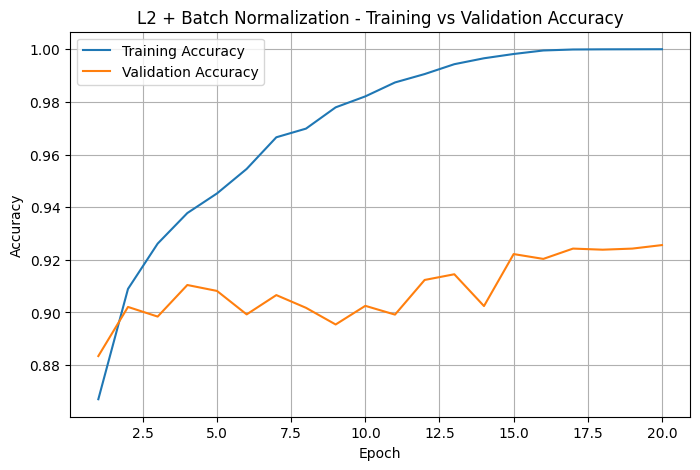

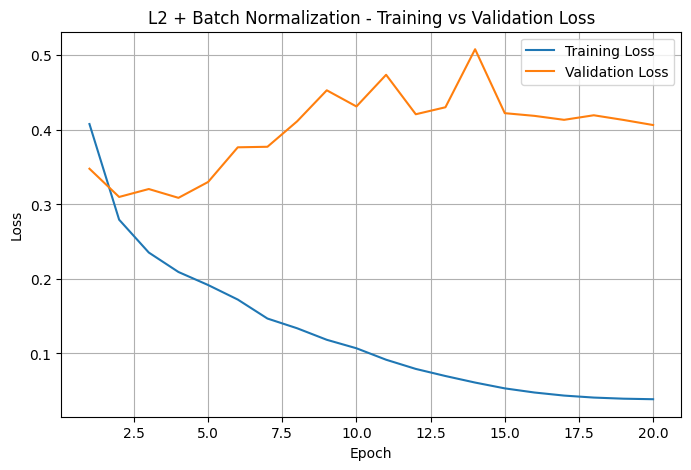

In [23]:
# ============================================================
# CELL 22: L2 + BATCH NORMALIZATION
# ============================================================

l2_batch_norm = train_experiment(

    experiment_name="L2 + Batch Normalization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    l2_strength=0.0001,

    use_batch_norm=True,

    epochs=TOTAL_EPOCHS
)

plot_history(l2_batch_norm)



EXPERIMENT: Dropout + Batch Normalization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 79s 102ms/step - accuracy: 0.7998 - loss: 0.5734 - val_accuracy: 0.8728 - val_loss: 0.3463 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 100ms/step - accuracy: 0.8622 - loss: 0.3844 - val_accuracy: 0.8943 - val_loss: 0.2848 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 75s 100ms/step - accuracy: 0.8826 - loss: 0.3284 - val_accuracy: 0.8998 - val_loss: 0.2657 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 99ms/step - accuracy: 0.8944 - loss: 0.2903 - val_accuracy: 0.9103 - val_loss: 0.2479 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 72s 97ms/step - accuracy: 0.9055 - loss: 0.2608 - val_accuracy: 0.9118 - val_loss: 0.2396 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 75s 99ms/step - accuracy: 0.9129 - loss: 0.2378 - val_accuracy: 0.8977 - val_loss: 0.2804 - learning_rate: 8.5355e-04
Epoch 7/2

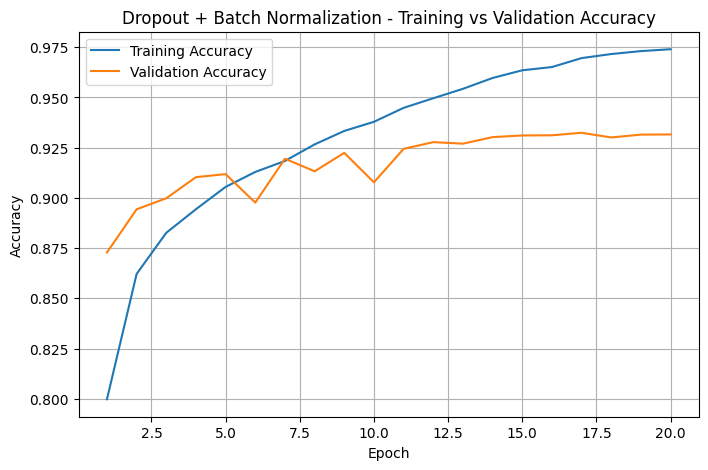

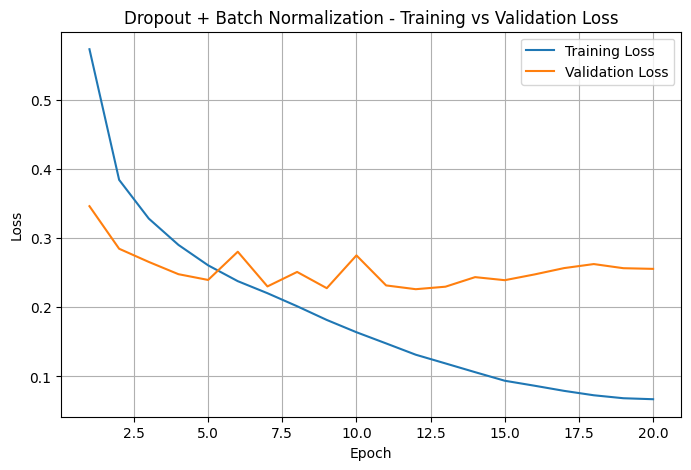

In [24]:
# ============================================================
# CELL 23: DROPOUT + BATCH NORMALIZATION
# ============================================================

dropout_batch_norm = train_experiment(

    experiment_name="Dropout + Batch Normalization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    dropout_rate=0.5,

    use_batch_norm=True,

    epochs=TOTAL_EPOCHS
)

plot_history(dropout_batch_norm)



EXPERIMENT: L2 + Dropout + Batch Normalization
Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 77s 99ms/step - accuracy: 0.7982 - loss: 0.6060 - val_accuracy: 0.8737 - val_loss: 0.3738 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 74s 99ms/step - accuracy: 0.8634 - loss: 0.4201 - val_accuracy: 0.8942 - val_loss: 0.3212 - learning_rate: 9.9384e-04
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 98ms/step - accuracy: 0.8802 - loss: 0.3720 - val_accuracy: 0.9002 - val_loss: 0.3159 - learning_rate: 9.7553e-04
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 72s 97ms/step - accuracy: 0.8945 - loss: 0.3387 - val_accuracy: 0.9061 - val_loss: 0.3029 - learning_rate: 9.4550e-04
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 76s 101ms/step - accuracy: 0.9034 - loss: 0.3138 - val_accuracy: 0.9043 - val_loss: 0.3153 - learning_rate: 9.0451e-04
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 98ms/step - accuracy: 0.9118 - loss: 0.2941 - val_accuracy: 0.9139 - val_loss: 0.2854 - learning_rate: 8.5355e-04
Epoch 

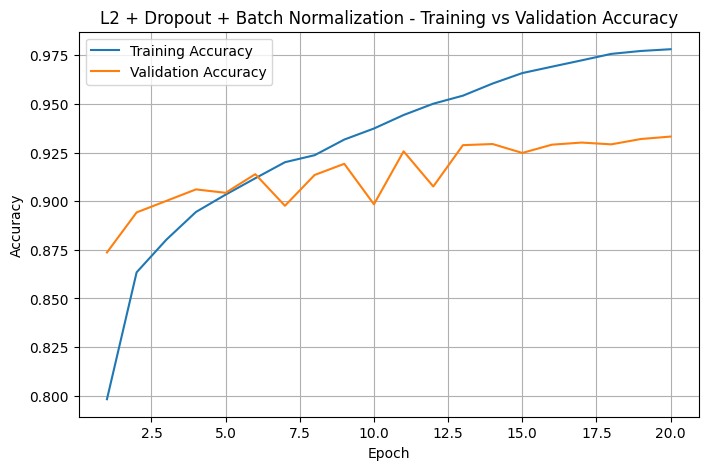

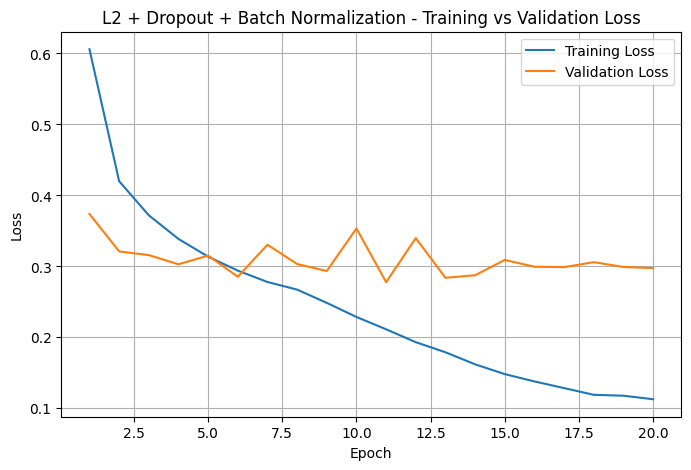

In [25]:
# ============================================================
# CELL 24: L2 + DROPOUT + BATCH NORMALIZATION
# ============================================================

all_regularization = train_experiment(

    experiment_name="L2 + Dropout + Batch Normalization",

    optimizer_name="Adam",

    learning_rate=0.001,

    schedule="cosine",

    l2_strength=0.0001,

    dropout_rate=0.5,

    use_batch_norm=True,

    epochs=TOTAL_EPOCHS
)

plot_history(all_regularization)

In [26]:
# ============================================================
# CELL 25: COLLECT ALL RESULTS
# ============================================================

all_results = [

    baseline,

    momentum,

    rmsprop,

    adam,

    adam_step,

    adam_cosine,

    no_regularization,

    l2_model,

    dropout_model,

    early_stop_model,

    batch_norm_model,

    l2_dropout,

    l2_batch_norm,

    dropout_batch_norm,

    all_regularization

]

print(
    "Total experiments:",
    len(all_results)
)

Total experiments: 15


In [27]:
# ============================================================
# CELL 26: VALIDATION RESULTS
# ============================================================

validation_results = []

for result in all_results:

    validation_results.append({

        "Experiment":
            result["name"],

        "Best Validation Accuracy":
            result["best_val_accuracy"],

        "Best Validation Loss":
            result["best_val_loss"],

        "Final Training Accuracy":
            result["final_train_accuracy"],

        "Final Validation Accuracy":
            result["final_val_accuracy"],

        "Training Time (sec)":
            result["training_time"]

    })


results_df = pd.DataFrame(
    validation_results
)


print(
    results_df.to_string(index=False)
)

                        Experiment  Best Validation Accuracy  Best Validation Loss  Final Training Accuracy  Final Validation Accuracy  Training Time (sec)
                    Baseline - SGD                  0.892250              0.300924                 0.899146                   0.892250          1416.518104
                    SGD + Momentum                  0.913583              0.257820                 0.972542                   0.899167          1299.900301
                           RMSprop                  0.913167              0.239340                 0.991271                   0.910250          1310.521824
                              Adam                  0.916333              0.243111                 0.989417                   0.912167          1227.876169
                 Adam + Step Decay                  0.918167              0.243025                 0.998208                   0.911333          1321.771664
           Adam + Cosine Annealing                  0.923417    

In [28]:
# ============================================================
# CELL 27: FORMATTED RESULTS
# ============================================================

display_df = results_df.copy()

display_df[
    "Best Validation Accuracy"
] = (
    display_df[
        "Best Validation Accuracy"
    ] * 100
).round(2)


display_df[
    "Best Validation Loss"
] = (
    display_df[
        "Best Validation Loss"
    ].round(4)
)


display_df[
    "Final Training Accuracy"
] = (
    display_df[
        "Final Training Accuracy"
    ] * 100
).round(2)


display_df[
    "Final Validation Accuracy"
] = (
    display_df[
        "Final Validation Accuracy"
    ] * 100
).round(2)


display_df[
    "Training Time (sec)"
] = (
    display_df[
        "Training Time (sec)"
    ].round(2)
)


display(display_df)

,Experiment,Best Validation Accuracy,Best Validation Loss,Final Training Accuracy,Final Validation Accuracy,Training Time (sec)
0,Baseline - SGD,89.23,0.3009,89.91,89.23,1416.52
1,SGD + Momentum,91.36,0.2578,97.25,89.92,1299.90
2,RMSprop,91.32,0.2393,99.13,91.03,1310.52
3,Adam,91.63,0.2431,98.94,91.22,1227.88
4,Adam + Step Decay,91.82,0.2430,99.82,91.13,1321.77
5,Adam + Cosine Annealing,92.34,0.2454,99.39,92.33,1324.62
6,No Regularization,92.08,0.2461,99.44,92.08,1433.49
7,L2 Regularization,92.42,0.2961,98.69,92.35,1327.30
8,Dropout,92.68,0.2142,95.85,92.67,1466.87
9,Early Stopping,91.60,0.2413,96.70,91.47,623.02


In [29]:
# ============================================================
# CELL 28: TEST SET EVALUATION
# ============================================================

test_results = []

for result in all_results:

    loss, accuracy = result["model"].evaluate(
        x_test,
        y_test,
        verbose=0
    )

    test_results.append({

        "Experiment":
            result["name"],

        "Test Loss":
            loss,

        "Test Accuracy":
            accuracy

    })


test_df = pd.DataFrame(
    test_results
)


test_display = test_df.copy()

test_display["Test Loss"] = (
    test_display["Test Loss"]
    .round(4)
)

test_display["Test Accuracy"] = (
    test_display["Test Accuracy"] * 100
).round(2)


display(test_display)

,Experiment,Test Loss,Test Accuracy
0,Baseline - SGD,0.3200,88.60
1,SGD + Momentum,0.3845,89.90
2,RMSprop,0.6591,90.60
3,Adam,0.5103,90.85
4,Adam + Step Decay,0.5231,90.48
5,Adam + Cosine Annealing,0.3525,91.84
6,No Regularization,0.3557,91.66
7,L2 Regularization,0.3163,92.29
8,Dropout,0.2410,92.37
9,Early Stopping,0.2618,90.67


In [30]:
# ============================================================
# CELL 29: BEST CONFIGURATION
# ============================================================

best_val_index = results_df[
    "Best Validation Accuracy"
].idxmax()


best_val_name = results_df.loc[
    best_val_index,
    "Experiment"
]


best_test_index = test_df[
    "Test Accuracy"
].idxmax()


best_test_name = test_df.loc[
    best_test_index,
    "Experiment"
]


best_test_accuracy = test_df.loc[
    best_test_index,
    "Test Accuracy"
]


print("=" * 60)

print(
    "BEST VALIDATION CONFIGURATION:"
)

print(best_val_name)


print("\n")


print(
    "BEST TEST CONFIGURATION:"
)

print(best_test_name)


print("\n")


print(
    "BEST TEST ACCURACY:",
    round(best_test_accuracy * 100, 2),
    "%"
)

print("=" * 60)

BEST VALIDATION CONFIGURATION:
L2 + Dropout + Batch Normalization


BEST TEST CONFIGURATION:
Dropout + Batch Normalization


BEST TEST ACCURACY: 92.79 %


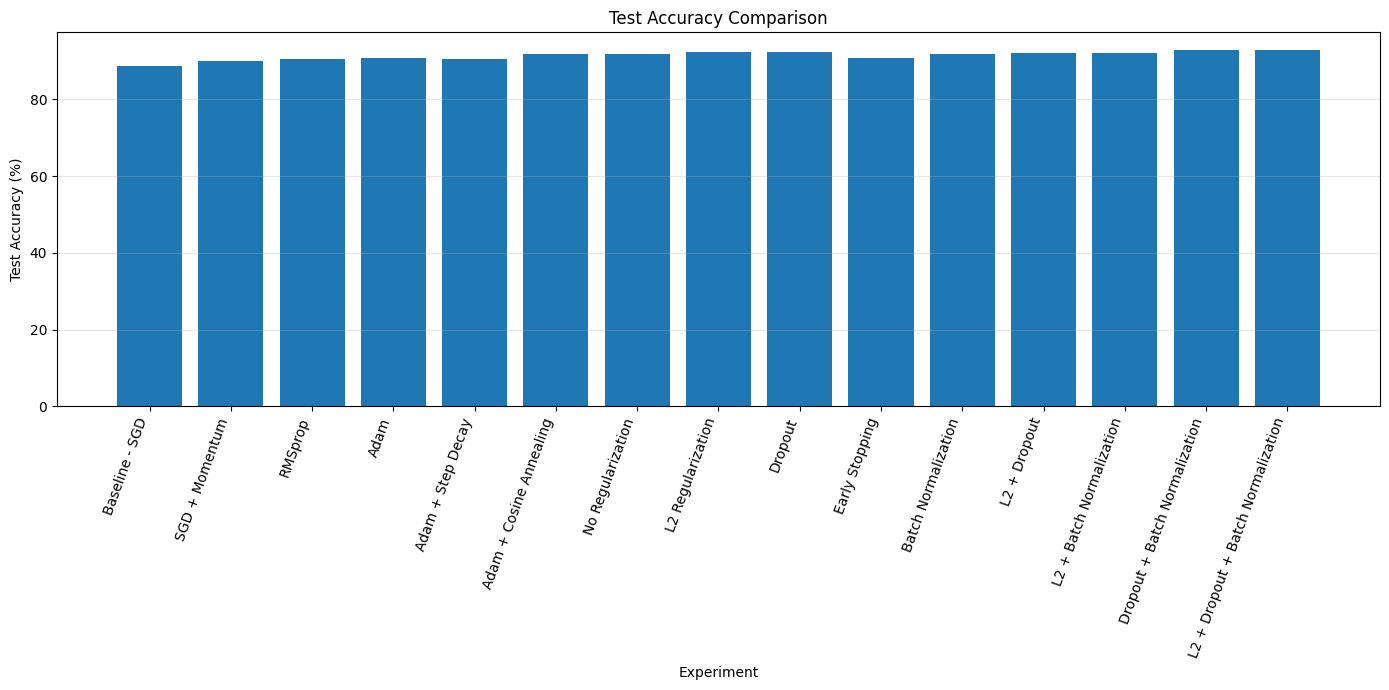

In [31]:
# ============================================================
# CELL 30: TEST ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(14, 7))

plt.bar(
    test_df["Experiment"],
    test_df["Test Accuracy"] * 100
)

plt.xlabel("Experiment")

plt.ylabel("Test Accuracy (%)")

plt.title(
    "Test Accuracy Comparison"
)

plt.xticks(
    rotation=70,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

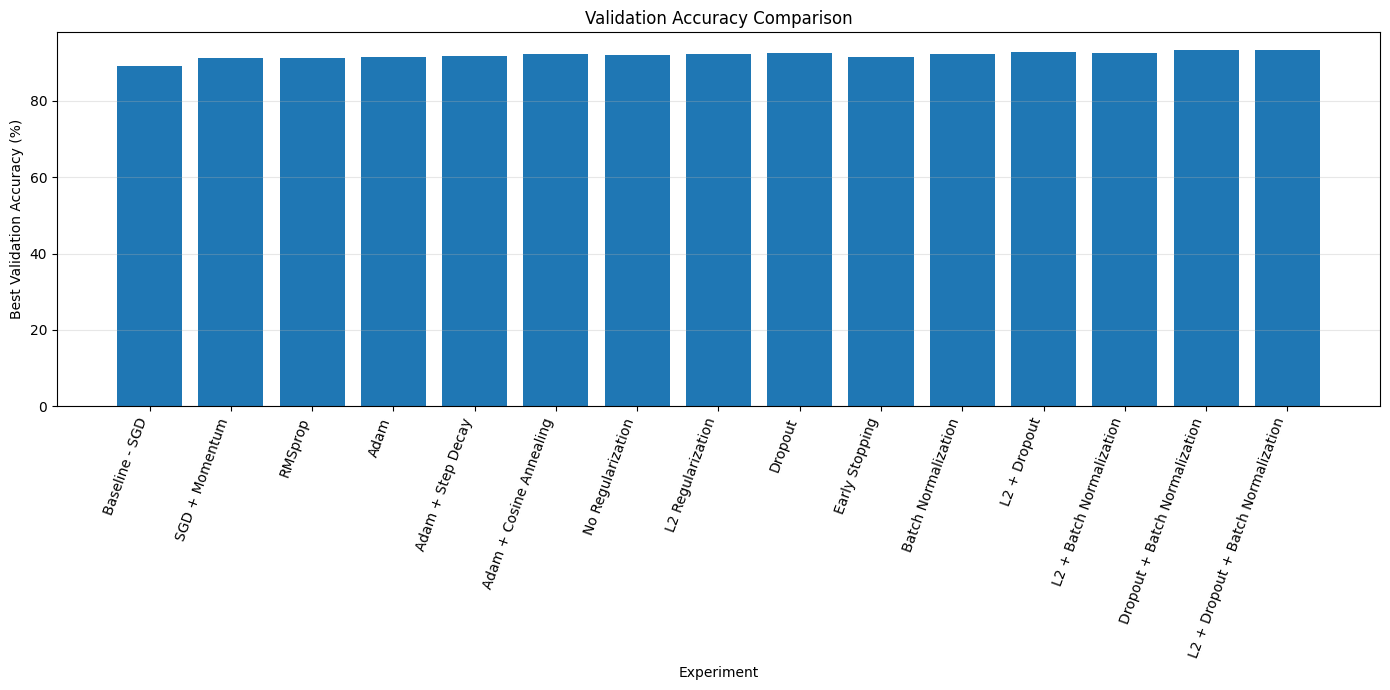

In [32]:
# ============================================================
# CELL 31: VALIDATION ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(14, 7))

plt.bar(
    results_df["Experiment"],
    results_df["Best Validation Accuracy"] * 100
)

plt.xlabel("Experiment")

plt.ylabel(
    "Best Validation Accuracy (%)"
)

plt.title(
    "Validation Accuracy Comparison"
)

plt.xticks(
    rotation=70,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

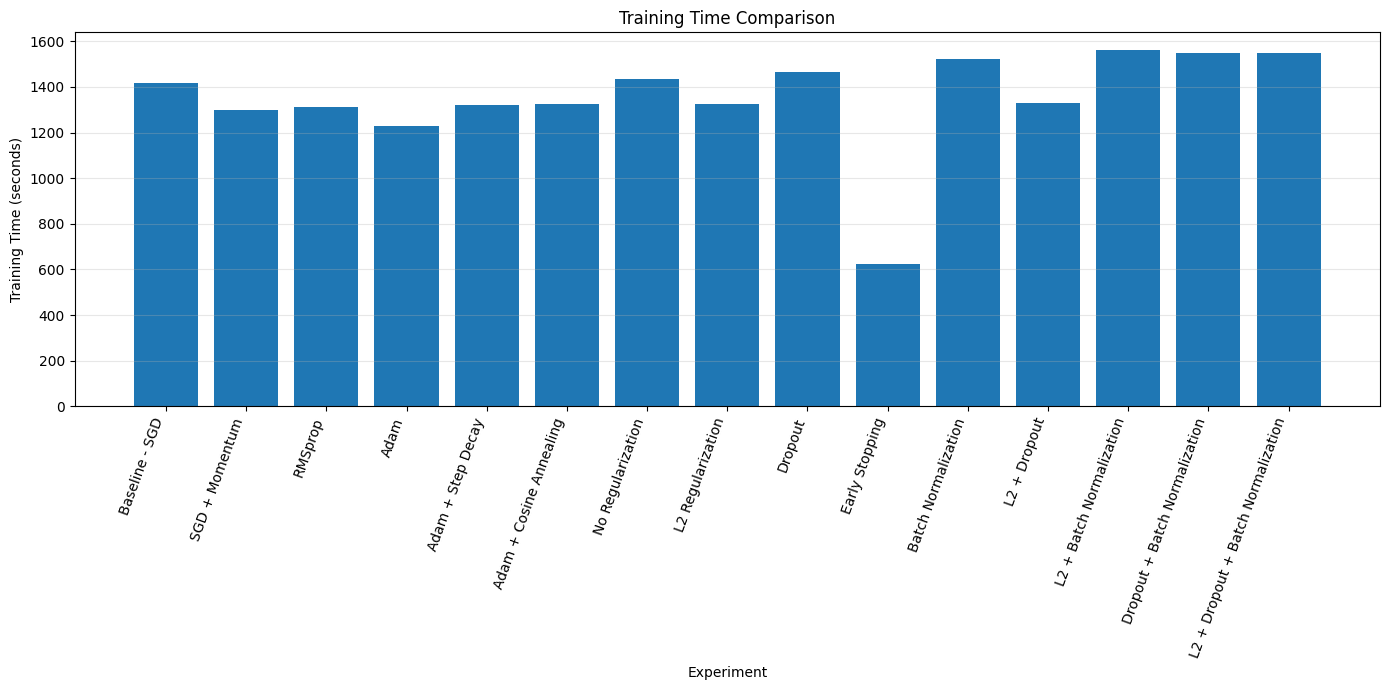

In [33]:
# ============================================================
# CELL 32: TRAINING TIME COMPARISON
# ============================================================

plt.figure(figsize=(14, 7))

plt.bar(
    results_df["Experiment"],
    results_df["Training Time (sec)"]
)

plt.xlabel("Experiment")

plt.ylabel(
    "Training Time (seconds)"
)

plt.title(
    "Training Time Comparison"
)

plt.xticks(
    rotation=70,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [34]:
# ============================================================
# CELL 33: SAVE RESULTS
# ============================================================

results_df.to_csv(
    "validation_results.csv",
    index=False
)

test_df.to_csv(
    "test_results.csv",
    index=False
)

print("Files saved successfully!")

print("validation_results.csv")
print("test_results.csv")

Files saved successfully!
validation_results.csv
test_results.csv


In [35]:
# ============================================================
# CELL 34: OVERFITTING ANALYSIS
# ============================================================

analysis_results = []

for result in all_results:

    train_acc = result[
        "final_train_accuracy"
    ]

    val_acc = result[
        "final_val_accuracy"
    ]

    gap = train_acc - val_acc

    if gap > 0.10:

        diagnosis = "Possible Overfitting"

    elif train_acc < 0.80 and val_acc < 0.80:

        diagnosis = "Possible Underfitting"

    else:

        diagnosis = "Reasonably Fitted"


    analysis_results.append({

        "Experiment":
            result["name"],

        "Training Accuracy":
            train_acc * 100,

        "Validation Accuracy":
            val_acc * 100,

        "Train-Val Gap":
            gap * 100,

        "Diagnosis":
            diagnosis

    })


analysis_df = pd.DataFrame(
    analysis_results
)


analysis_df[
    "Training Accuracy"
] = analysis_df[
    "Training Accuracy"
].round(2)


analysis_df[
    "Validation Accuracy"
] = analysis_df[
    "Validation Accuracy"
].round(2)


analysis_df[
    "Train-Val Gap"
] = analysis_df[
    "Train-Val Gap"
].round(2)


display(analysis_df)

,Experiment,Training Accuracy,Validation Accuracy,Train-Val Gap,Diagnosis
0,Baseline - SGD,89.91,89.23,0.69,Reasonably Fitted
1,SGD + Momentum,97.25,89.92,7.34,Reasonably Fitted
2,RMSprop,99.13,91.03,8.10,Reasonably Fitted
3,Adam,98.94,91.22,7.73,Reasonably Fitted
4,Adam + Step Decay,99.82,91.13,8.69,Reasonably Fitted
5,Adam + Cosine Annealing,99.39,92.33,7.06,Reasonably Fitted
6,No Regularization,99.44,92.08,7.36,Reasonably Fitted
7,L2 Regularization,98.69,92.35,6.34,Reasonably Fitted
8,Dropout,95.85,92.67,3.18,Reasonably Fitted
9,Early Stopping,96.70,91.47,5.22,Reasonably Fitted
